# 02. Área 1: Campañas de Marketing (A1 - Supervisado)
**Materia:** INF432 - Sistemas para el Soporte a la Toma de Decisiones  
**Proyecto:** Minería de datos para decisiones comerciales - RetailMarket Santa Cruz  
**Autor (Integrante 1):** Diogo Nicolas Rodríguez Gómez (Reg. 221045686)  

### Pregunta de Negocio
Con un presupuesto limitado de contacto directo, ¿a qué clientes debe dirigirse la próxima campaña comercial para maximizar la tasa de aceptación (`Response` = 1) y minimizar el costo de adquisición de clientes?

### Decisión, decisor y criterio de éxito
- **Decisión que apoya:** a qué clientes contactar en la próxima campaña.
- **Quién decide:** Gerente de Marketing.
- **Criterio de éxito:** contactando al 20 % de los clientes, captar al menos el 40 % de las aceptaciones (el doble de lo esperado al azar) y obtener ganancia positiva en prueba. Debe coincidir con la Sección 2 del documento.

### Metodología de Modelado (Requisito R5)
- **Modelos a comparar:** k-Nearest Neighbors (kNN), Naive Bayes Gaussiano y Árbol de Decisión.
- **Optimización:** Búsqueda en grilla con validación cruzada (`GridSearchCV`) sobre el conjunto de entrenamiento para kNN y Árbol de Decisión.
- **Evaluación:** Evaluación estricta sobre el conjunto de prueba (`test_scaled.csv`, 30% ciego) analizando la exactitud, matriz de confusión y el costo del negocio de falsos positivos vs. falsos negativos.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve
)

# Fijar semilla global obligatoria
SEMILLA = 1
np.random.seed(SEMILLA)

# 1. Cargar datos preprocesados desde data/processed/
train_df = pd.read_csv('data/processed/train_scaled.csv')
test_df = pd.read_csv('data/processed/test_scaled.csv')

# Separar atributos predictores (X) y variable objetivo (y)
X_train = train_df.drop(columns=['Response'])
y_train = train_df['Response']

X_test = test_df.drop(columns=['Response'])
y_test = test_df['Response']

print(f"Dimensiones de entrenamiento (X_train): {X_train.shape}")
print(f"Dimensiones de prueba (X_test): {X_test.shape}")


Dimensiones de entrenamiento (X_train): (1422, 28)
Dimensiones de prueba (X_test): (610, 28)


### 5.2.1 Modelo 1: k-Nearest Neighbors (kNN)
Optimizamos el hiperparámetro $k$ (`n_neighbors`) evaluando valores impares entre 3 y 25, y probando distancias euclidiana y manhattan con 5 pliegues de validación cruzada (`cv=5`).

In [2]:
# Grilla de hiperparámetros para kNN
param_grid_knn = {
    'n_neighbors': list(range(3, 27, 2)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn = KNeighborsClassifier()
grid_knn = GridSearchCV(knn, param_grid_knn, cv=5, scoring='f1', n_jobs=-1)
grid_knn.fit(X_train, y_train)

best_knn = grid_knn.best_estimator_
print("Parámetros óptimos para kNN:", grid_knn.best_params_)

# Predicciones sobre el conjunto de prueba
y_pred_knn = best_knn.predict(X_test)
y_prob_knn = best_knn.predict_proba(X_test)[:, 1]

acc_knn = accuracy_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)

print(f"kNN en Prueba -> Exactitud: {acc_knn:.4f} | F1-Score: {f1_knn:.4f} | AUC: {auc_knn:.4f}")

Parámetros óptimos para kNN: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'uniform'}
kNN en Prueba -> Exactitud: 0.8639 | F1-Score: 0.4354 | AUC: 0.7566


### 5.2.2 Modelo 2: Naive Bayes Gaussiano
El clasificador Naive Bayes asume independencia condicional entre los predictores y distribuciones normales en los atributos numéricos continuos. No requiere ajuste pesado de hiperparámetros y sirve como punto de referencia probabilístico rápido.

In [3]:
# Entrenar Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)

# Predicciones en prueba
y_pred_nb = nb.predict(X_test)
y_prob_nb = nb.predict_proba(X_test)[:, 1]

acc_nb = accuracy_score(y_test, y_pred_nb)
rec_nb = recall_score(y_test, y_pred_nb)
prec_nb = precision_score(y_test, y_pred_nb)
f1_nb = f1_score(y_test, y_pred_nb)
auc_nb = roc_auc_score(y_test, y_prob_nb)

print(f"Naive Bayes en Prueba -> Exactitud: {acc_nb:.4f} | F1-Score: {f1_nb:.4f} | AUC: {auc_nb:.4f}")

Naive Bayes en Prueba -> Exactitud: 0.8197 | F1-Score: 0.4954 | AUC: 0.8084


### 5.2.3 Modelo 3: Árbol de Decisión (Decision Tree)
Optimizamos la profundidad máxima (`max_depth`), el criterio de partición (`gini` vs. `entropy`) y el número mínimo de muestras por hoja (`min_samples_leaf`) para evitar el sobreajuste (*overfitting*) y obtener reglas interpretables de negocio.

In [4]:
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 8, 10],
    'min_samples_leaf': [5, 10, 15, 20]
}

dt = DecisionTreeClassifier(random_state=SEMILLA)
grid_dt = GridSearchCV(dt, param_grid_dt, cv=5, scoring='f1', n_jobs=-1)
grid_dt.fit(X_train, y_train)

best_dt = grid_dt.best_estimator_
print("Parámetros óptimos para Árbol de Decisión:", grid_dt.best_params_)

# Predicciones en prueba
y_pred_dt = best_dt.predict(X_test)
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

acc_dt = accuracy_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

print(f"Árbol de Decisión en Prueba -> Exactitud: {acc_dt:.4f} | F1-Score: {f1_dt:.4f} | AUC: {auc_dt:.4f}")

Parámetros óptimos para Árbol de Decisión: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 20}
Árbol de Decisión en Prueba -> Exactitud: 0.8377 | F1-Score: 0.4407 | AUC: 0.8438


### 5.2.4 Comparación de Modelos y Matrices de Confusión
Evaluamos las matrices de confusión de los tres modelos en el conjunto de prueba para contrastar los **Falsos Positivos (FP)** (costo de contactar a un cliente que no compra) y los **Falsos Negativos (FN)** (costo de oportunidad por perder un cliente que sí habría aceptado la oferta).

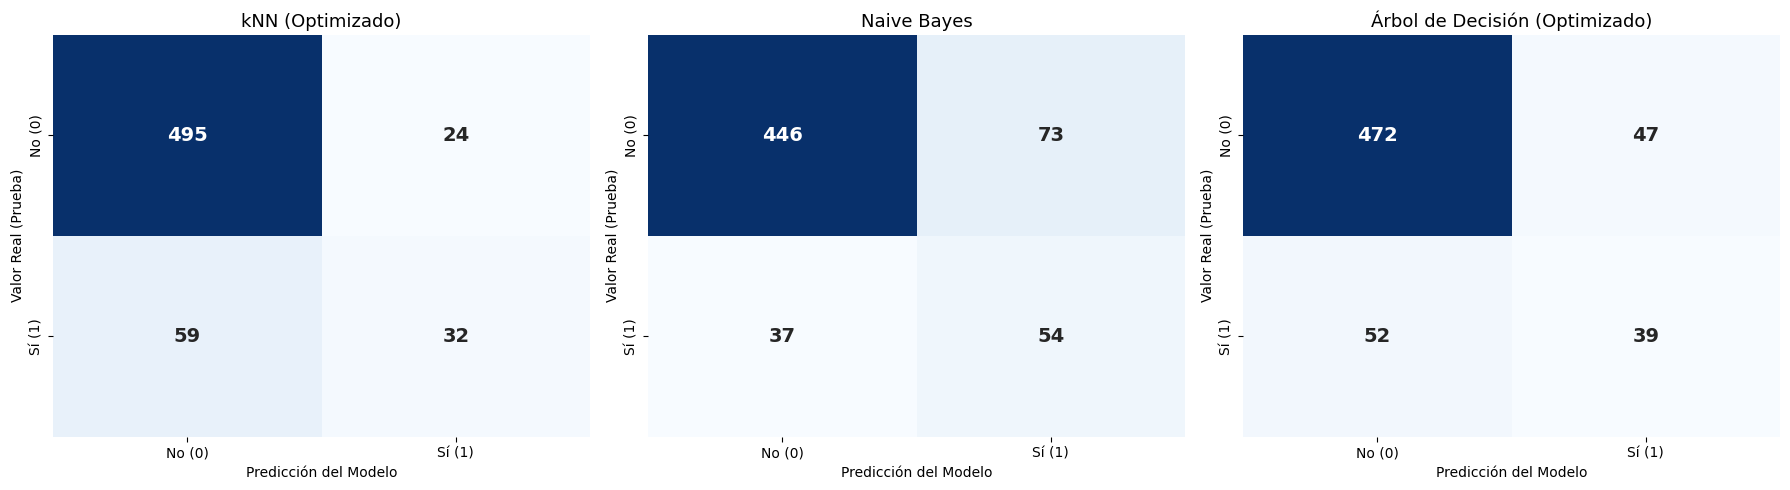

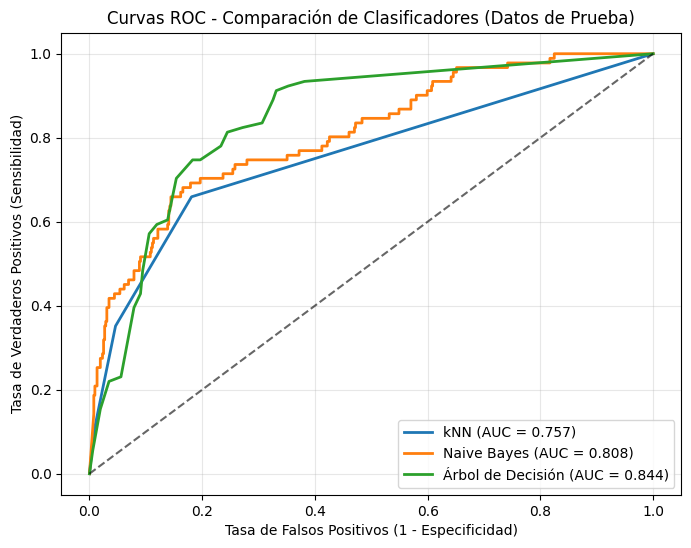

In [5]:
# 1. Gráfico de Matrices de Confusión
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

modelos_dict = {
    'kNN (Optimizado)': (y_pred_knn, axes[0]),
    'Naive Bayes': (y_pred_nb, axes[1]),
    'Árbol de Decisión (Optimizado)': (y_pred_dt, axes[2])
}

for nombre, (preds, ax) in modelos_dict.items():
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'})
    ax.set_title(nombre, fontsize=13)
    ax.set_xlabel('Predicción del Modelo')
    ax.set_ylabel('Valor Real (Prueba)')
    ax.set_xticklabels(['No (0)', 'Sí (1)'])
    ax.set_yticklabels(['No (0)', 'Sí (1)'])

plt.tight_layout()
plt.savefig('reports/figures/matrices_confusion_A1.png', dpi=300)
plt.show()

# 2. Curvas ROC comparativas
plt.figure(figsize=(8, 6))
for nombre, probas in [('kNN', y_prob_knn), ('Naive Bayes', y_prob_nb), ('Árbol de Decisión', y_prob_dt)]:
    fpr, tpr, _ = roc_curve(y_test, probas)
    auc = roc_auc_score(y_test, probas)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {auc:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.6)
plt.title('Curvas ROC - Comparación de Clasificadores (Datos de Prueba)')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.savefig('reports/figures/curvas_roc_A1.png', dpi=300)
plt.show()

### 5.2.5 Resumen de Rendimiento y Análisis Económico de Errores
Construimos la tabla consolidada en los datos de prueba y calculamos los porcentajes exactos de Falsos Positivos y Falsos Negativos requeridos para la plantilla del documento.

In [6]:
# Función para calcular porcentajes de FP y FN sobre el total de prueba
def calcular_tasas_error(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    total = len(y_true)
    pct_fp = (fp / total) * 100
    pct_fn = (fn / total) * 100
    return pct_fp, pct_fn

fp_knn, fn_knn = calcular_tasas_error(y_test, y_pred_knn)
fp_nb, fn_nb = calcular_tasas_error(y_test, y_pred_nb)
fp_dt, fn_dt = calcular_tasas_error(y_test, y_pred_dt)

# Armar dataframe consolidado
df_resultados_a1 = pd.DataFrame({
    'Modelo': ['kNN', 'Naive Bayes', 'Árbol de decisión'],
    'Parámetros óptimos': [
        f"k = {grid_knn.best_params_['n_neighbors']}, metric = '{grid_knn.best_params_['metric']}'",
        '— (GaussianNB estándar)',
        f"criterion = '{grid_dt.best_params_['criterion']}', max_depth = {grid_dt.best_params_['max_depth']}, min_leaf = {grid_dt.best_params_['min_samples_leaf']}"
    ],
    'Exactitud en prueba': [f"{acc_knn:.2%}", f"{acc_nb:.2%}", f"{acc_dt:.2%}"],
    '% falsos positivos': [f"{fp_knn:.2f}%", f"{fp_nb:.2f}%", f"{fp_dt:.2f}%"],
    '% falsos negativos': [f"{fn_knn:.2f}%", f"{fn_nb:.2f}%", f"{fn_dt:.2f}%"],
    'F1-Score': [f"{f1_knn:.4f}", f"{f1_nb:.4f}", f"{f1_dt:.4f}"],
    'AUC-ROC': [f"{auc_knn:.4f}", f"{auc_nb:.4f}", f"{auc_dt:.4f}"]
})

print("=== TABLA PARA EL DOCUMENTO WORD (SECCIÓN 5.2.3) ===")
display(df_resultados_a1)

=== TABLA PARA EL DOCUMENTO WORD (SECCIÓN 5.2.3) ===


,Modelo,Parámetros óptimos,Exactitud en prueba,% falsos positivos,% falsos negativos,F1-Score,AUC-ROC
0,kNN,"k = 3, metric = 'manhattan'",86.39%,3.93%,9.67%,0.4354,0.7566
1,Naive Bayes,— (GaussianNB estándar),81.97%,11.97%,6.07%,0.4954,0.8084
2,Árbol de decisión,"criterion = 'entropy', max_depth = 10, min_lea...",83.77%,7.70%,8.52%,0.4407,0.8438


### 5.2.6 Importancia de Variables en el Árbol de Decisión
Extraemos las variables con mayor peso predictivo según el Árbol de Decisión para traducir el hallazgo técnico a recomendaciones accionables para el equipo comercial de RetailMarket Santa Cruz.

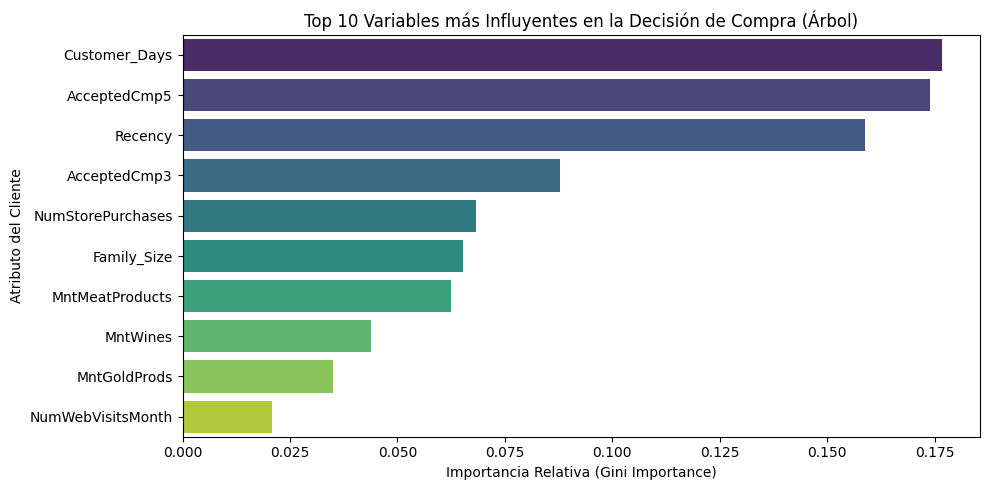

Top 5 variables más críticas para el negocio:
Customer_Days        0.1767
AcceptedCmp5         0.1740
Recency              0.1587
AcceptedCmp3         0.0878
NumStorePurchases    0.0683


In [7]:
importancias = pd.Series(best_dt.feature_importances_, index=X_train.columns)
importancias_top10 = importancias.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=importancias_top10.values, y=importancias_top10.index, hue=importancias_top10.index, palette='viridis', legend=False)
plt.title('Top 10 Variables más Influyentes en la Decisión de Compra (Árbol)')
plt.xlabel('Importancia Relativa (Gini Importance)')
plt.ylabel('Atributo del Cliente')
plt.tight_layout()
plt.savefig('reports/figures/importancia_variables_A1.png', dpi=300)
plt.show()

print("Top 5 variables más críticas para el negocio:")
print(importancias_top10.head(5).round(4).to_string())


### 5.2.7 Costo de los errores para el negocio

Los datos incluyen el costo y el ingreso de la campaña: cada contacto cuesta 3 unidades monetarias (UM) y cada aceptación deja 11 UM. Estos valores permiten traducir los errores a dinero:

- **Falso positivo (FP):** se contacta a quien no acepta. Se pierden 3 UM.
- **Falso negativo (FN):** no se contacta a quien habría aceptado. Se dejan de ganar 8 UM (11 − 3).

Dejar pasar a un cliente interesado cuesta casi el triple que un contacto inútil. Por eso la exactitud no basta para elegir el modelo.

Evaluamos dos formas de usar cada modelo en los datos de prueba: contactar a quienes predice como positivos, y contactar al 20 % con mayor probabilidad, que responde al presupuesto limitado de la pregunta de negocio.

In [8]:
# Costo e ingreso del conjunto de datos original
datos_crudos = pd.read_csv('data/raw/marketing_campaign.csv', sep='\t')
COSTO_CONTACTO = int(datos_crudos['Z_CostContact'].iloc[0])
INGRESO_ACEPTACION = int(datos_crudos['Z_Revenue'].iloc[0])

total_aceptan = int(y_test.sum())
contactos_20 = int(round(0.20 * len(y_test)))

filas_costo = []

for nombre, preds, probas in [
    ('kNN', y_pred_knn, y_prob_knn),
    ('Naive Bayes', y_pred_nb, y_prob_nb),
    ('Árbol de decisión', y_pred_dt, y_prob_dt)
]:
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

    # Los clientes con mayor probabilidad; el orden estable hace repetible el resultado
    mejores = np.argsort(-probas, kind='stable')[:contactos_20]
    aceptan_20 = int(y_test.iloc[mejores].sum())

    filas_costo.append({
        'Modelo': nombre,
        'FP': fp,
        'FN': fn,
        'Costo FP (UM)': fp * COSTO_CONTACTO,
        'Ingreso perdido FN (UM)': fn * (INGRESO_ACEPTACION - COSTO_CONTACTO),
        'Contactos': tp + fp,
        'Ganancia (UM)': INGRESO_ACEPTACION * tp - COSTO_CONTACTO * (tp + fp),
        'Aceptaciones en el 20 %': aceptan_20,
        'Captura en el 20 % (%)': aceptan_20 / total_aceptan * 100,
        'Ganancia en el 20 % (UM)': INGRESO_ACEPTACION * aceptan_20 - COSTO_CONTACTO * contactos_20
    })

tabla_costos_a1 = pd.DataFrame(filas_costo)
display(tabla_costos_a1.round(1))

print(f"Clientes en prueba: {len(y_test)} | Aceptan: {total_aceptan} | Contactos del 20 %: {contactos_20}")
print(f"Ganancia si se contacta a todos: {INGRESO_ACEPTACION * total_aceptan - COSTO_CONTACTO * len(y_test)} UM")

os.makedirs('reports/tables', exist_ok=True)
tabla_costos_a1.to_csv('reports/tables/A1_costos_modelos.csv', index=False, encoding='utf-8-sig')
df_resultados_a1.to_csv('reports/tables/A1_resultados_modelos.csv', index=False, encoding='utf-8-sig')

,Modelo,FP,FN,Costo FP (UM),Ingreso perdido FN (UM),Contactos,Ganancia (UM),Aceptaciones en el 20 %,Captura en el 20 % (%),Ganancia en el 20 % (UM)
0,kNN,24,59,72,472,56,184,52,57.1,206
1,Naive Bayes,73,37,219,296,127,213,53,58.2,217
2,Árbol de decisión,47,52,141,416,86,171,55,60.4,239


Clientes en prueba: 610 | Aceptan: 91 | Contactos del 20 %: 122
Ganancia si se contacta a todos: -829 UM


**Interpretación.** Contactar a todos los clientes de prueba perdería 829 UM, porque solo 91 de 610 aceptan. Cualquiera de los tres modelos vuelve positiva la campaña.

Con el presupuesto del 20 % (122 contactos), el **árbol de decisión** es el mejor: capta 55 de las 91 aceptaciones (60,4 %) y gana 239 UM, frente a 217 UM de Naive Bayes y 206 UM de kNN. Cumple el criterio de éxito.

Sin límite de presupuesto, Naive Bayes logra la mayor ganancia (213 UM con 127 contactos). kNN parece el mejor por exactitud (86,39 %), pero contacta a solo 56 clientes y deja pasar 59 aceptaciones. Esto muestra por qué la exactitud sola sería engañosa.

Las probabilidades del árbol y de kNN tienen pocos valores distintos, por lo que hay empates al elegir el 20 %. Esos empates se resuelven por orden de fila, lo que afecta un poco la cifra exacta.

### 5.2.8 Estabilidad frente a la división de datos

Una sola división 70/30 puede dar un resultado favorable o desfavorable por azar. Repetimos 30 divisiones distintas para Naive Bayes y para el árbol, con sus parámetros ya elegidos, y medimos exactitud y captura en el 20 %. Esta prueba solo evalúa la estabilidad: los resultados oficiales son los de la semilla acordada.

In [9]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

base_estabilidad = pd.read_csv('data/processed/data_limpia_original.csv')
X_base = base_estabilidad.drop(columns=['Response'])
y_base = base_estabilidad['Response']

filas_estabilidad = []

for nombre, modelo in [('Naive Bayes', nb), ('Árbol de decisión', best_dt)]:
    exactitudes, capturas = [], []

    for semilla in range(1, 31):
        X_a, X_b, y_a, y_b = train_test_split(
            X_base, y_base, test_size=0.30, random_state=semilla, stratify=y_base
        )
        escalador = StandardScaler().fit(X_a)
        ajustado = clone(modelo).fit(escalador.transform(X_a), y_a)

        X_b_escalado = escalador.transform(X_b)
        probas = ajustado.predict_proba(X_b_escalado)[:, 1]
        mejores = np.argsort(-probas, kind='stable')[:int(round(0.20 * len(y_b)))]

        exactitudes.append(accuracy_score(y_b, ajustado.predict(X_b_escalado)) * 100)
        capturas.append(y_b.iloc[mejores].sum() / y_b.sum() * 100)

    filas_estabilidad.append({
        'Modelo': nombre,
        'Exactitud media (%)': np.mean(exactitudes),
        'Exactitud mínima (%)': np.min(exactitudes),
        'Exactitud máxima (%)': np.max(exactitudes),
        'Captura media en el 20 % (%)': np.mean(capturas),
        'Captura mínima (%)': np.min(capturas),
        'Captura máxima (%)': np.max(capturas)
    })

tabla_estabilidad_a1 = pd.DataFrame(filas_estabilidad)
display(tabla_estabilidad_a1.round(1))
tabla_estabilidad_a1.to_csv('reports/tables/A1_estabilidad_modelos.csv', index=False, encoding='utf-8-sig')

,Modelo,Exactitud media (%),Exactitud mínima (%),Exactitud máxima (%),Captura media en el 20 % (%),Captura mínima (%),Captura máxima (%)
0,Naive Bayes,79.4,53.9,82.6,54.3,46.2,60.4
1,Árbol de decisión,84.9,82.5,86.9,54.7,47.3,62.6


**Lectura.** El árbol es mucho más estable: su exactitud va de 82,5 % a 86,9 %, mientras que Naive Bayes promedia 79,4 % pero cayó a 53,9 % en una división. Esto explica por qué un resultado aislado de Naive Bayes no es fiable.

En captura con el 20 % de contactos ambos son equivalentes (54,7 % y 54,3 % de media). El 60,4 % de la prueba oficial está en la parte alta de lo observado, por lo que lo esperable ronda el 55 %, que sigue superando la meta de 40 %.

### 5.2.9 Respuesta, recomendaciones, despliegue y monitoreo

**Respuesta a la pregunta de negocio.** La campaña debe dirigirse al 20 % de clientes con mayor probabilidad según el árbol de decisión. Contactar a todos genera pérdida; priorizar permite captar más de la mitad de las aceptaciones con una quinta parte de los contactos.

**Modelo recomendado: árbol de decisión.** Tiene la mayor captura y ganancia en la prueba oficial, una captura igual de buena que Naive Bayes en las 30 divisiones y reglas que el equipo comercial puede entender.

**Qué distingue a quienes aceptan.** Las variables con más peso son `Customer_Days`, `AcceptedCmp5`, `Recency`, `AcceptedCmp3` y `NumStorePurchases`. Quienes aceptaron llevan más tiempo como clientes (445 frente a 336 días), compraron más recientemente (35 frente a 52 días) y aceptaron más campañas anteriores (27 % frente a 4 % en la campaña 5). Son asociaciones, no causas.

**Recomendaciones.**
1. No contactar a toda la base.
2. Priorizar a clientes con historial de aceptación, compra reciente y mayor antigüedad.
3. Usar exactitud junto con ganancia y captura, porque un FN cuesta casi el triple que un FP.

**Puesta en práctica.** Antes de cada campaña, el analista de datos aplica a los clientes elegibles la misma preparación (mediana de `Income` y escalador de entrenamiento) y el árbol ya entrenado, sin volver a ajustarlos. Entrega la lista ordenada por probabilidad y el Gerente de Marketing define cuántos contactar según el presupuesto. Antes de usarlo a gran escala se propone un piloto con un grupo de control elegido al azar, para medir el efecto real.

**Monitoreo.**

| Indicador | Cálculo | Frecuencia | Alerta propuesta |
|---|---|---|---|
| Captura | Aceptaciones del grupo contactado / aceptaciones totales del piloto | Por campaña | Menor al 40 % |
| Tasa de aceptación | Aceptaciones / contactos | Por campaña | Menor a 25 % |
| Ganancia | 11 × aceptaciones − 3 × contactos, con los valores vigentes | Por campaña | Valor negativo |
| Efecto incremental | Tasa del grupo contactado − tasa del grupo de control | Al terminar el piloto | Sin diferencia a favor |
| Datos de entrada | Faltantes, duplicados y cambios en la distribución de las variables | Antes de cada uso | Corregir antes de puntuar |

Estos umbrales son propuestas operativas, pendientes de validar. Se reentrenará si la captura cae bajo la alerta en dos campañas seguidas, después de descartar errores de carga.

**Limitaciones.** Los datos son simulados, por lo que la ganancia es ilustrativa. El conjunto de prueba tiene solo 91 aceptaciones. Costo e ingreso son valores fijos del caso; una campaña real debe usar los suyos. El modelo apoya la decisión, pero no reemplaza el criterio comercial, y no debe excluir clientes de beneficios por sus características personales.